In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("transaction.csv")
df['transaction_date'] = pd.to_datetime(df['transaction_date'])

df_success = df.loc[df['status'] == 'Success'].copy()
df_success['month'] = df_success['transaction_date'].dt.to_period('M')


In [2]:
df.head()


In [8]:
total_revenue = df_success['amount'].sum()
total_txn = df_success.shape[0]
avg_txn = df_success['amount'].mean()




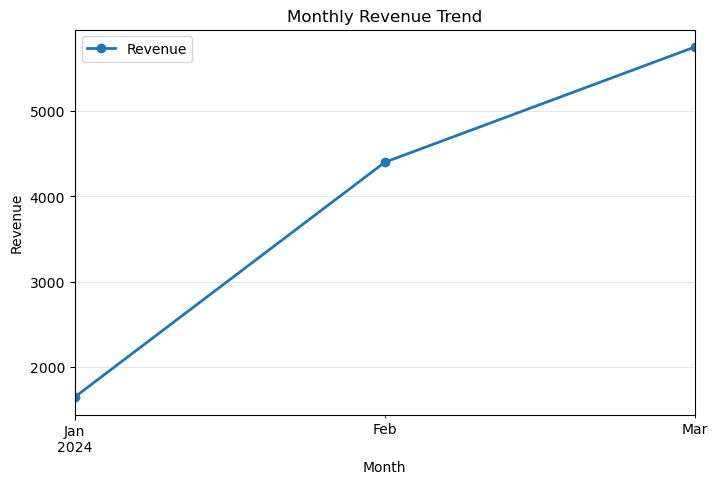

In [4]:
monthly_revenue = df_success.groupby('month')['amount'].sum()

plt.figure(figsize=(8,5))
monthly_revenue.plot(marker='o', linewidth=2, label='Revenue')

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
#Revenue shows consistent month-on-month growth.

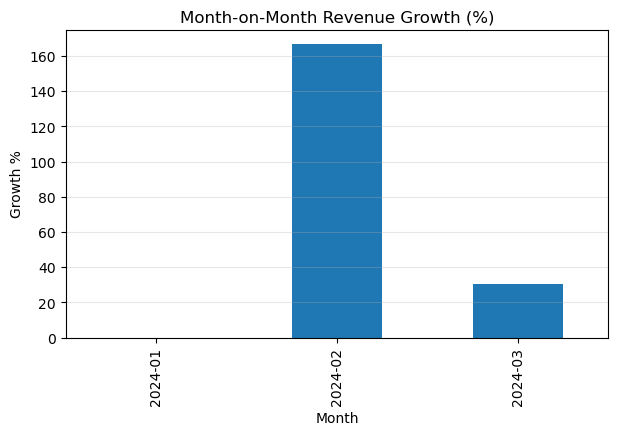

In [5]:
growth = monthly_revenue.pct_change() * 100

plt.figure(figsize=(7,4))
growth.plot(kind='bar')

plt.title("Month-on-Month Revenue Growth (%)")
plt.xlabel("Month")
plt.ylabel("Growth %")
plt.grid(axis='y', alpha=0.3)
plt.show()
#Positive growth indicates increasing adoption of fintech services.

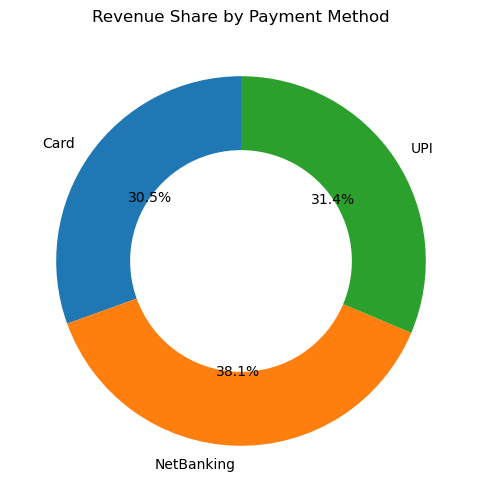

In [9]:
payment_rev = df_success.groupby('transaction_type')['amount'].sum()

fig, ax = plt.subplots(figsize=(6,6))
ax.pie(
    payment_rev,
    labels=payment_rev.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(width=0.4)
)

ax.set_title("Revenue Share by Payment Method")
plt.show()
#A small set of customers drives a large portion of revenue.

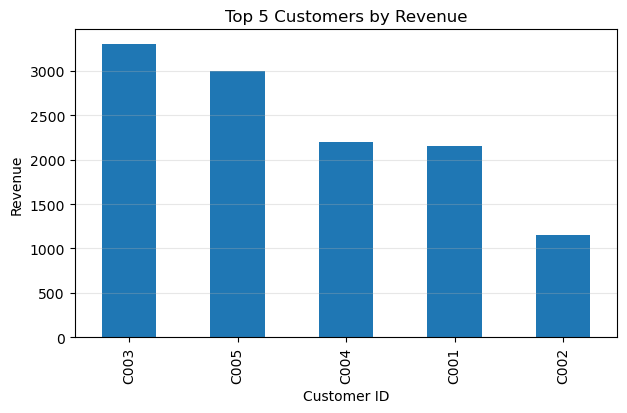

In [10]:
top_customers = (
    df_success.groupby('customer_id')['amount']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7,4))
top_customers.head(5).plot(kind='bar')

plt.title("Top 5 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")
plt.grid(axis='y', alpha=0.3)
plt.show()


In [11]:
cust_rev = df_success.groupby('customer_id')['amount'].sum()

segments = pd.qcut(
    cust_rev,
    q=3,
    labels=['Low Value', 'Medium Value', 'High Value']
)

seg_df = pd.DataFrame({
    'Revenue': cust_rev,
    'Segment': segments
})


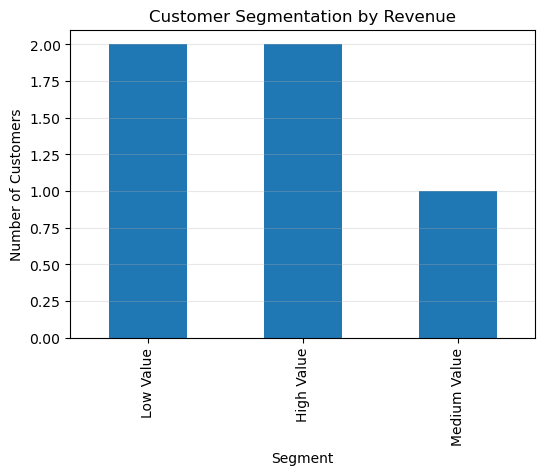

In [14]:
plt.figure(figsize=(6,4))
seg_df['Segment'].value_counts().plot(kind='bar')

plt.title("Customer Segmentation by Revenue")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.grid(axis='y', alpha=0.3)
plt.show()
#High-value customers are fewer but strategically critical.

## Executive Summary
This analysis highlights steady revenue growth, dominance of digital
payment methods, and the importance of high-value customers.
The insights can support strategic decisions around customer retention
and payment optimization.